# **Machine Learning-Based Forecasting of the PSEi**
The objective of this model is to **forecast the upcoming week's PSEi** (approximately 5 trading days) based on features such as OHLC (open, high, low, and closing prices), 50-day simple moving average, volume, volatility (measured using wilder's average true range), and momentum (measured using 14-day RSI). The model may be used to give traders and investors a guide on the direction and change of stock prices the following week.



While the model predicts the PSEi, specific stocks of choice may still be used as inputs and may be predicted by the model. I just chose the PSEi because other than it serves as the benchmark of the Philippine stock market, it spares me the burden of having to decide which stock to pick xD.

## **The Dataset**
For this project, I used **15 years worth of PSEi historical records**, spanning from October 2011 to October 2026 where I started this project. I got the dataset [here (Investing.com PSEi Composite)](https://ph.investing.com/indices/psei-composite-historical-data).


The original dataset contains 3,659 rows including only date, OHLC, and volume, so other metrics such as SMA, volatility, and momentum, **I derived and computed manually on Excel** (formulas to be given later). The actual data used in this model contains 50+ less rows in order to account for the moving average and next week prices.

The downloaded PSEi data has no missing values, and I also cleaned the data already when I was in Excel, so **very minimal data cleaning and transformation will be seen in this notebook**.

## **Computations**

### **50-day Simple Moving Average (Trend)**
This is just the average closing price of the last 50 days. Computed simply as

$SMA_{50} = \frac{1}{50}\sum_{i=1}^{50} p_i$


### **Wilder's Volatility (Volatility)**
Measures a stock’s average price movement over a specified number of trading periods, accounting for price gaps, making it useful for assessing market volatility and setting stop-loss levels. Unlike standard deviation, it measures volatility in absolute price units rather than dispersion around the mean. The main value here is the 14-day **Average True Range**, computed for day $i$ as

$ATR_i = \frac{14 \cdot ATR_{i-1}+TR_i}{14}$

Where the true range (TR) for day $i$ is computed by

$TR_i = \max\begin{cases}
H_i - L_i\\
|H_i - C_{i-1}|\\
|L_i - C_{i-1}|
\end{cases}$

where $H_i$ is the current day's high, $L_i$ is the current day's low, and $C_{i-1}$ is the previous day's closing price.

### **14-Day Relative Strength Index (Momentum)**
Measures the speed and magnitude of recent price gains relative to losses to assess momentum and identify potentially overbought or oversold conditions. Unlike simple momentum indicators, it uses Wilder’s smoothing method to balance recent price changes with historical movements on a bounded 0–100 scale. For day $i$,

$RSI_i = 100 - \frac{100}{1 + RS_i}$

where

$RS_i = \frac{\text{14-Day Average Gain}}{\text{14-Day Average Loses}}$

## **Exploratory Data Analysis**

In [40]:
# necessary imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [41]:
# loading data from google drive

from google.colab import drive
drive.mount('/content/drive')

psei_df_1 = pd.read_csv('/content/drive/MyDrive/Projects/PSEi Weekly Forecasting Model/psei_data.csv')
psei_df_1.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Date,Price,Open,High,Low,Volume,SMA,Volatility,Momentum,% Week Change,TR,Gain,Loss,Average Gain,Average Loss,Vol (Scratch),Next Week Price
0,10/08/2026,5610.39,5727.76,5744.40,5610.39,102370,6044.87,79.51,34.360190,0.940755,134.01,0.00,126.30,19.264286,36.801429,102.37K,5663.17
1,10/07/2026,5736.69,5688.55,5736.69,5688.55,82760,6058.74,75.32,35.423918,-2.082385,59.57,59.57,0.00,19.264286,35.117857,82.76K,5617.23
2,10/06/2026,5677.12,5733.53,5733.53,5677.12,70990,6070.31,76.53,33.871792,0.430148,66.09,0.00,66.09,17.987857,35.117857,70.99K,5701.54
3,10/05/2026,5743.21,5676.82,5743.21,5643.06,43360,6082.38,77.33,32.780547,-0.000522,114.18,114.18,0.00,17.987857,36.885714,43.36K,5743.18
4,10/02/2026,5629.03,5653.42,5663.75,5589.59,83260,6093.18,74.49,19.082541,1.278373,74.16,0.00,0.44,9.832143,41.692143,83.26K,5700.99


In [42]:
# removing unnecessary features, converting to date, checking datatypes, and other checks

features = ["Date", "Price", "Open", "High", "Low", "Volume", "SMA", "Momentum", "Volatility", "Next Week Price"]
psei_df = psei_df_1[features]
psei_df["Date"] = pd.to_datetime(psei_df["Date"])
psei_df.head()
psei_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3603 entries, 0 to 3602
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             3603 non-null   datetime64[ns]
 1   Price            3603 non-null   float64       
 2   Open             3603 non-null   float64       
 3   High             3603 non-null   float64       
 4   Low              3603 non-null   float64       
 5   Volume           3603 non-null   int64         
 6   SMA              3603 non-null   float64       
 7   Momentum         3603 non-null   float64       
 8   Volatility       3603 non-null   float64       
 9   Next Week Price  3603 non-null   float64       
dtypes: datetime64[ns](1), float64(8), int64(1)
memory usage: 281.6 KB


/tmp/ipykernel_2666/3256139830.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  psei_df["Date"] = pd.to_datetime(psei_df["Date"])


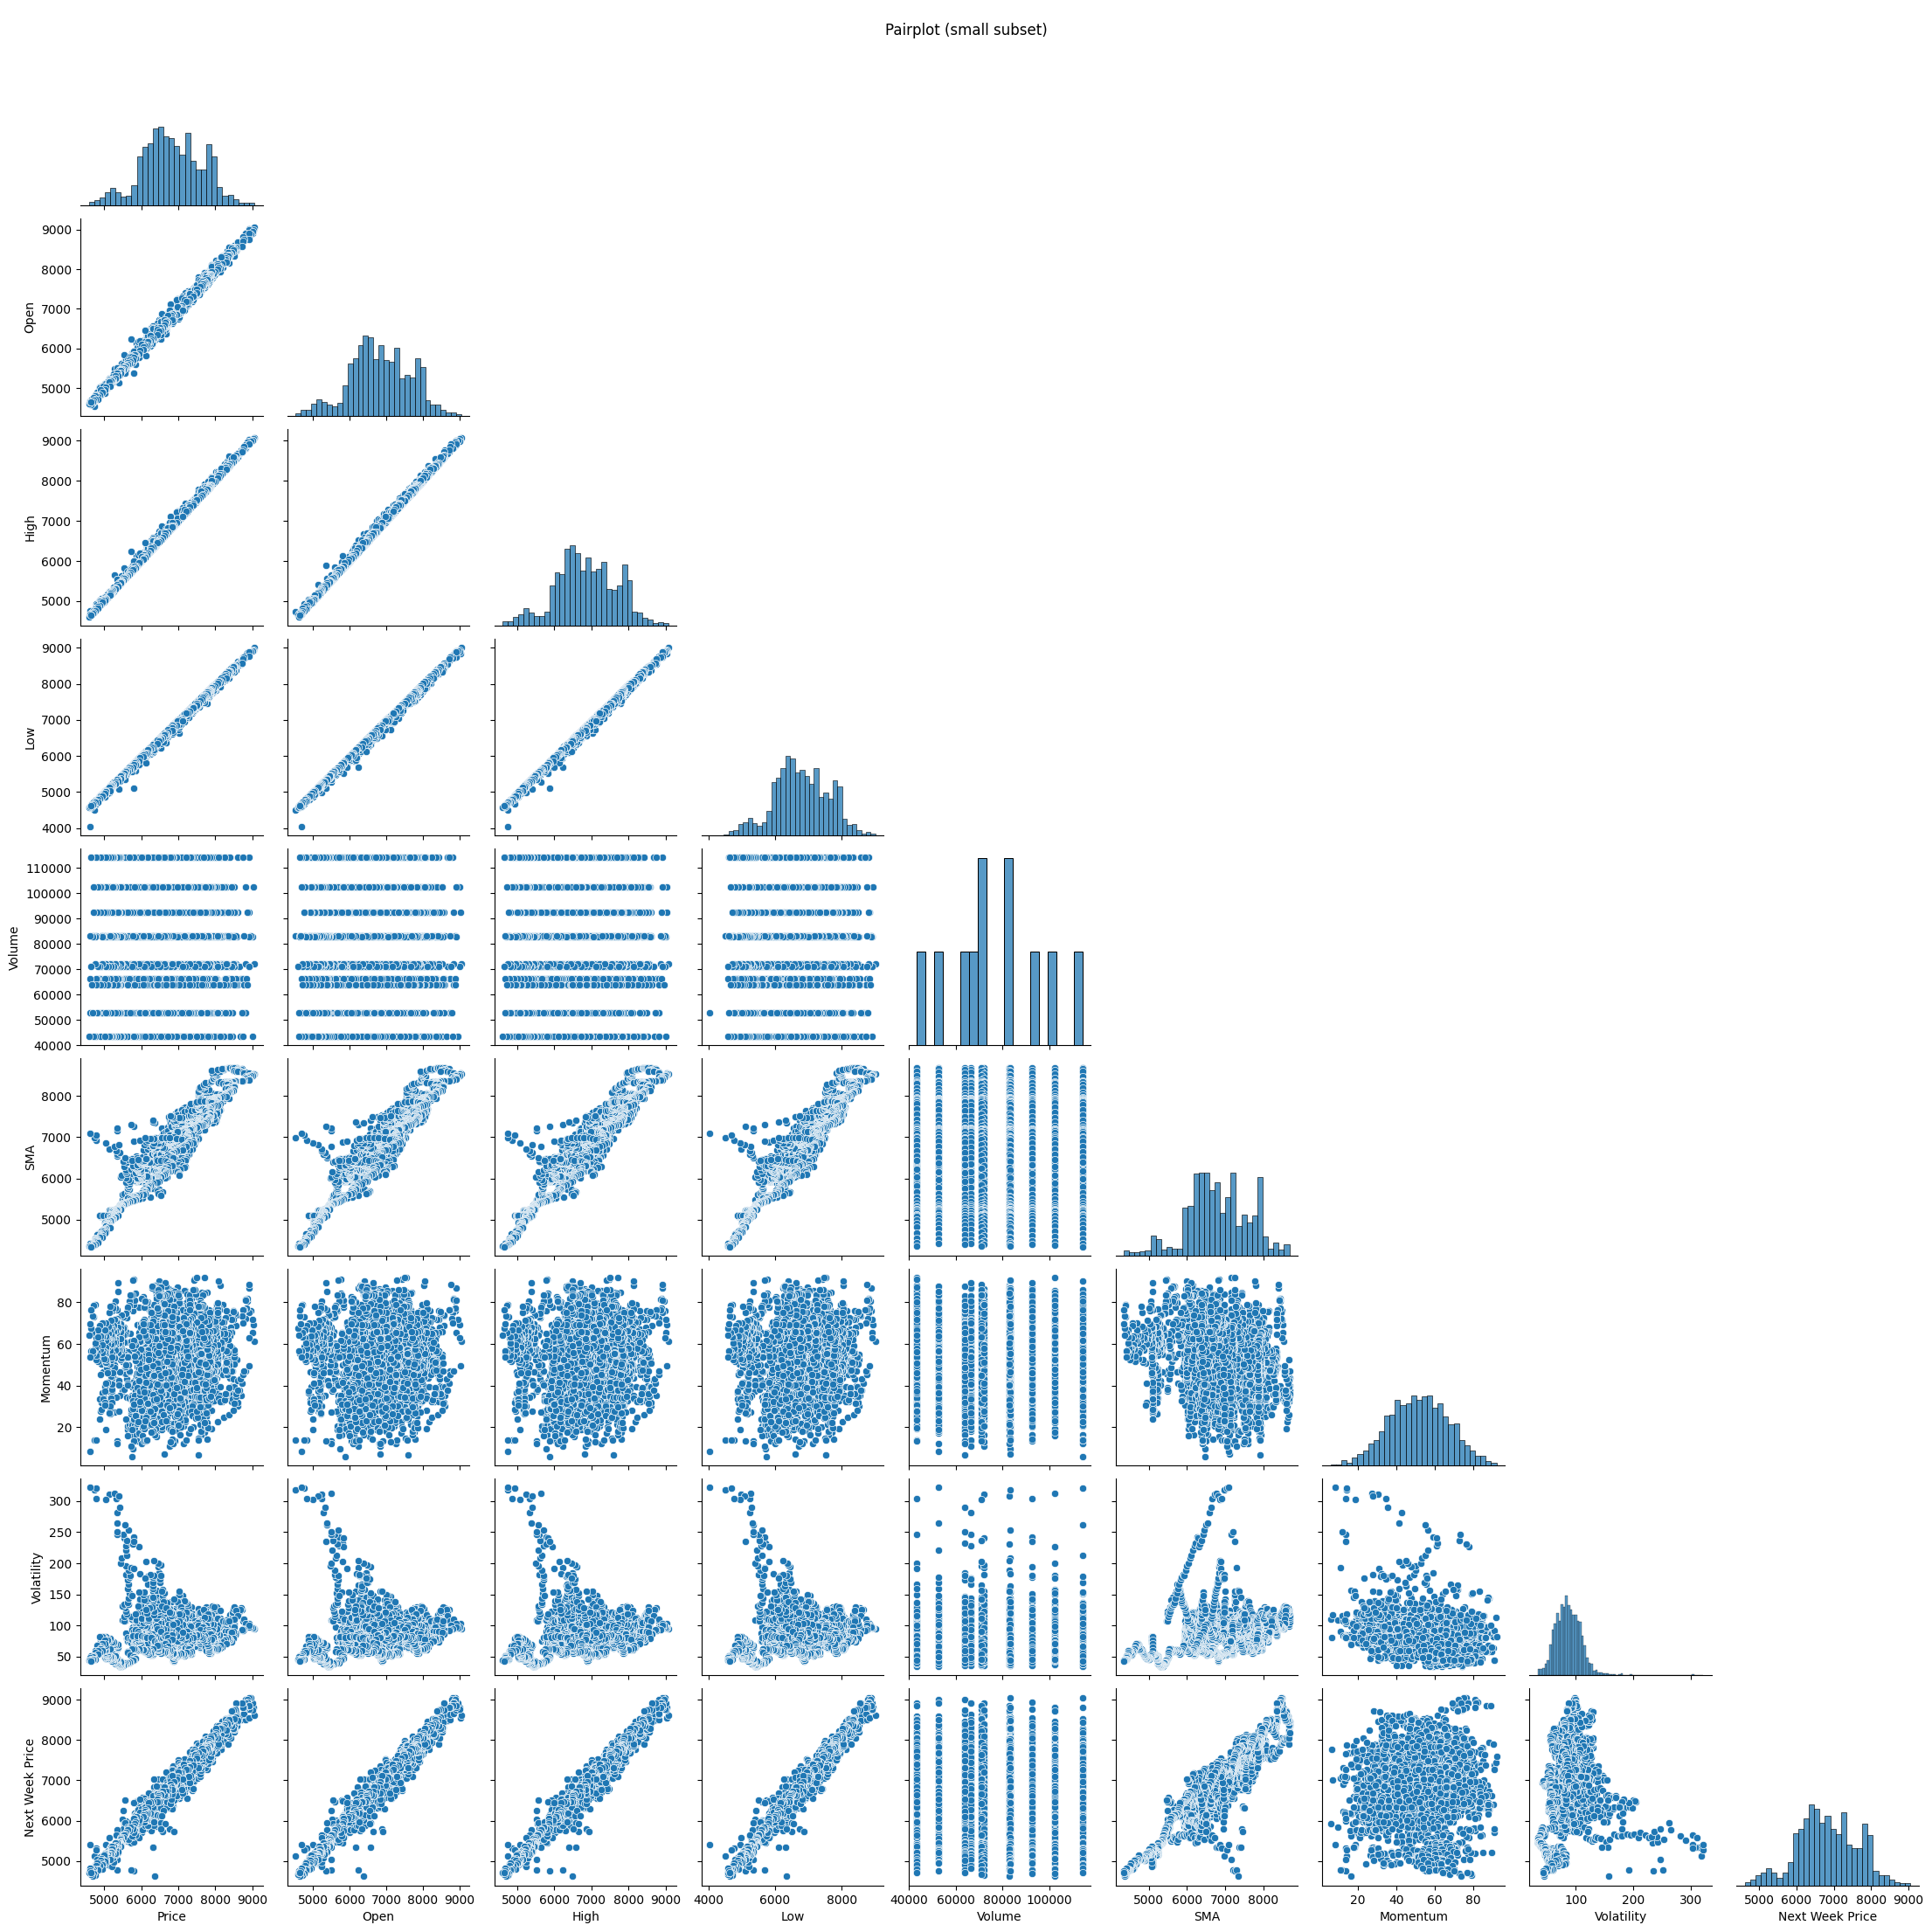

In [43]:
# pairplot of numerical values

sns.pairplot(psei_df, corner=True)
plt.suptitle('Pairplot (small subset)')
plt.show()

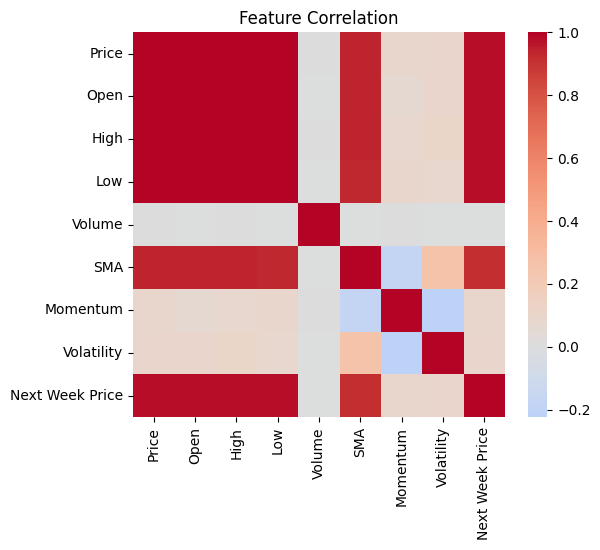

In [44]:
# feature correlation

plt.figure(figsize=(6, 5))

corr = psei_df.select_dtypes(include=['int64', 'float64']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0)

plt.title('Feature Correlation')
plt.show()

In [45]:
# removing null values and checking dataset shape. datasize is still good

display(psei_df.isnull().sum())
psei_df.dropna(inplace=True)
psei_df.shape

,0
Date,0
Price,0
Open,0
High,0
Low,0
Volume,0
SMA,0
Momentum,0
Volatility,0
Next Week Price,0


/tmp/ipykernel_2666/4108076573.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  psei_df.dropna(inplace=True)


(3603, 10)

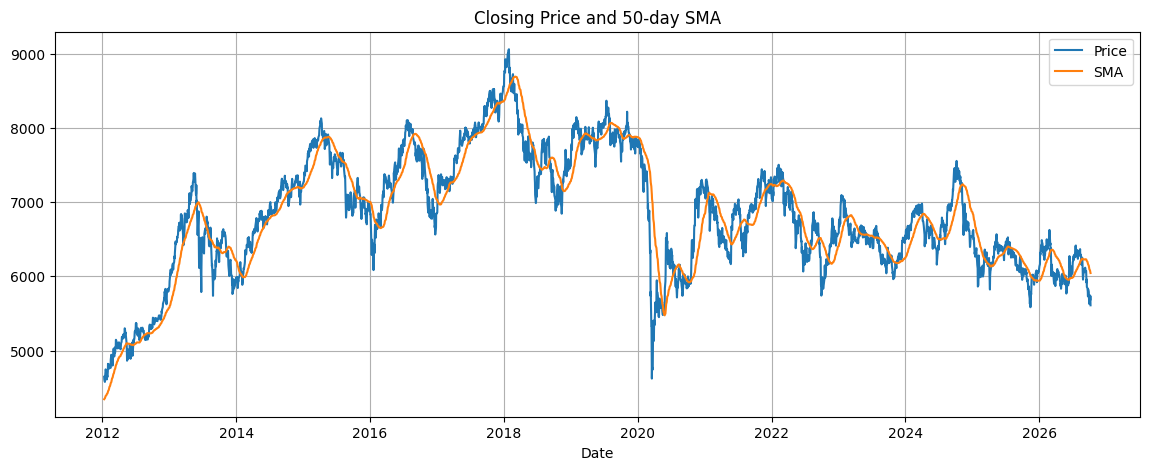

In [46]:
# closing price and 50-day sma

plt.figure(figsize=(14, 5))
plt.plot(psei_df['Date'], psei_df['Price'], label="Price")
plt.plot(psei_df['Date'], psei_df['SMA'], label="SMA")

plt.title("Closing Price and 50-day SMA")
plt.xlabel("Date")
plt.legend()
plt.grid(True)

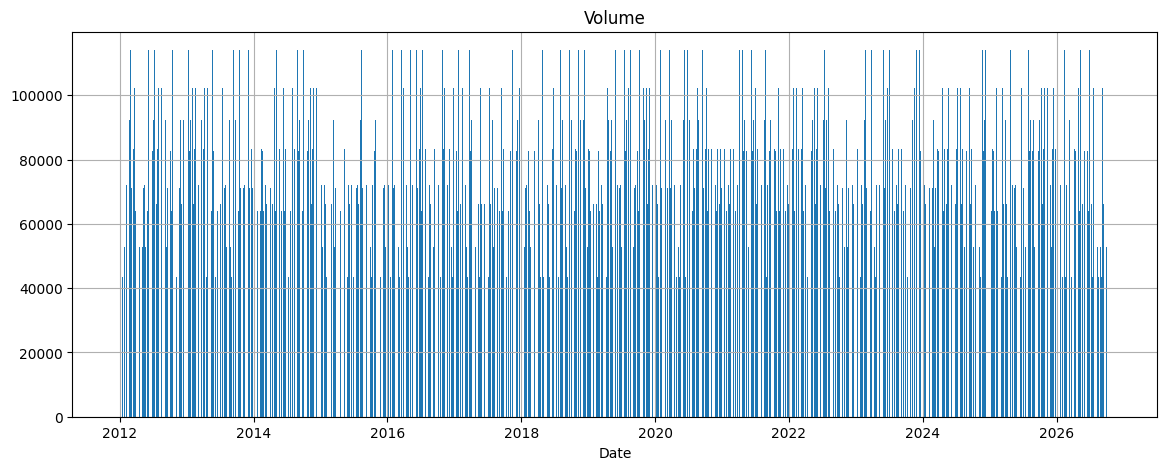

In [47]:
# volume
plt.figure(figsize=(14, 5))
plt.bar(psei_df['Date'], psei_df['Volume'])

plt.title("Volume")
plt.xlabel("Date")
plt.grid(True)

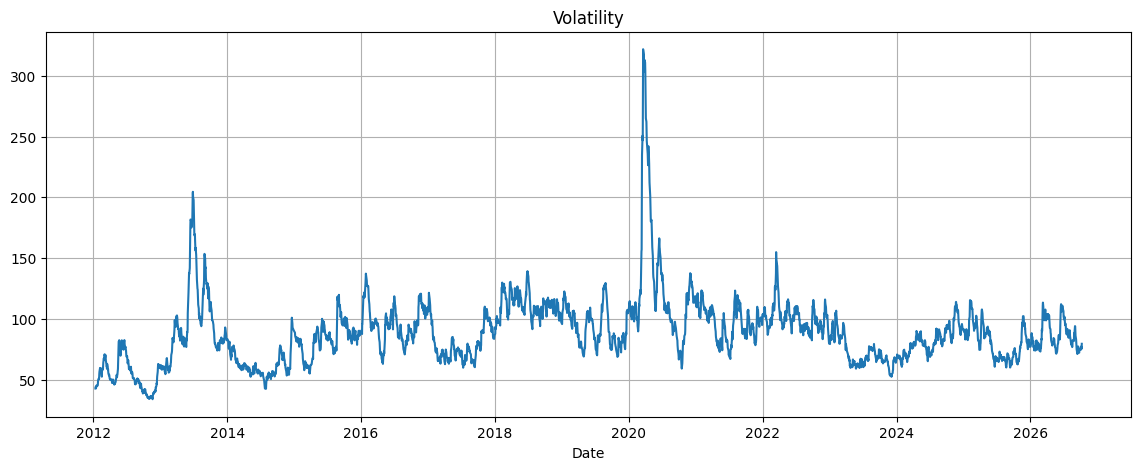

In [48]:
# volatility
plt.figure(figsize=(14, 5))
plt.plot(psei_df['Date'], psei_df['Volatility'], label="SMA")

plt.title("Volatility")
plt.xlabel("Date")
plt.grid(True)

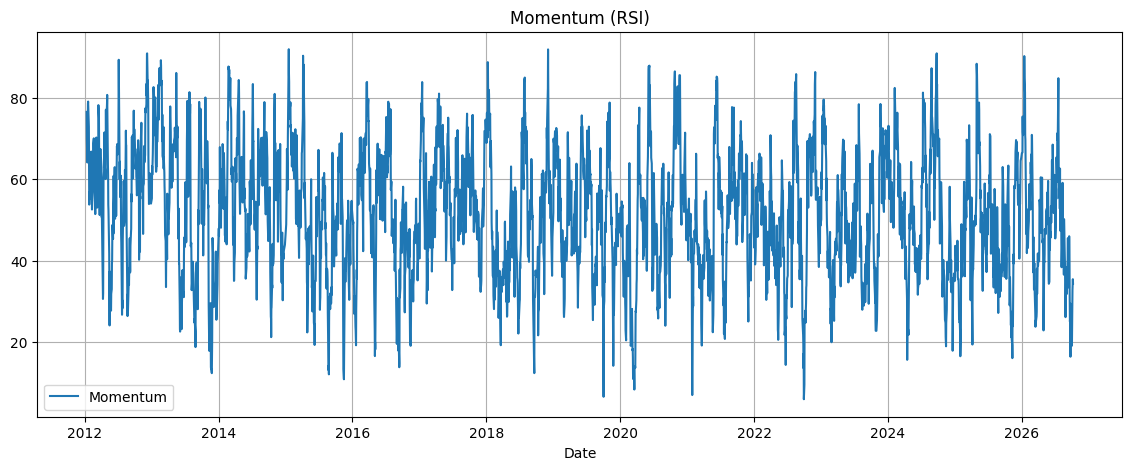

In [49]:
# momentum (rsi)
plt.figure(figsize=(14, 5))
plt.plot(psei_df['Date'], psei_df['Momentum'], label="Momentum")

plt.title("Momentum (RSI)")
plt.xlabel("Date")
plt.legend()
plt.grid(True)

## **Splitting Data**


In [50]:
# uses chronological split so that it trains on older data

test_start = int(len(psei_df) * 0.2)

X = psei_df.drop(columns=["Next Week Price", "Date"])
y = psei_df["Next Week Price"]

# test on the newest 20%
Xr_test = X.iloc[:test_start]
yr_test = y.iloc[:test_start]

# Exclude a 5-row gap, then train on older observations
Xr_train = X.iloc[test_start + 5:]
yr_train = y.iloc[test_start + 5:]

## **Model Training**

**Note:** While we aim to optimize every metric (minimize MAE, MSE, AND RMSE and maximize $R^2$), hyperparameter finetuning was done primarily with the goal of minimizing the MSE to inflate the effect of errors.

Key metrics are defined below:

*   **Mean Absolute Error (MAE)** - The average difference between the actual and the predicted.
*   **Mean Squared Error (MSE)** - The average squared difference between the actual and the predicted.
*   **Root Mean Squared Error (RMSE)** - The square root of the average squared prediction errors.
*   **$R^2$** - The proportion of the data that is explained by the predictors.

Note also that I have tried using libraries such as **TimeSeriesSplit, GridSearch, and RandomizedSearchCV** for tuning but it didn't yield results as good enough as when I manually tuned the parameters myself (xD).

### **Linear Regression**

In [51]:
# linear regression

lr = LinearRegression()
lr.fit(Xr_train, yr_train)
lr_predictions = lr.predict(Xr_test)

results = []

results.append({"Model": "Linear Regression",
        "MAE": mean_absolute_error(yr_test, lr_predictions),
        "MSE": mean_squared_error(yr_test, lr_predictions),
        "RMSE": np.sqrt(mean_squared_error(yr_test, lr_predictions)),
        "R²": r2_score(yr_test, lr_predictions)
    })

metrics_df = pd.DataFrame(results)
print(metrics_df.round(4))

               Model      MAE         MSE      RMSE      R²
0  Linear Regression  103.073  17476.3246  132.1981  0.8779


### **Random Forest**

In [52]:
# random forest

rf = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=30, random_state=8)
rf.fit(Xr_train, yr_train)
rf_predictions = rf.predict(Xr_test)

results = []

results.append({"Model": "Random Forest Regressor",
        "MAE": mean_absolute_error(yr_test, rf_predictions),
        "MSE": mean_squared_error(yr_test, rf_predictions),
        "RMSE": np.sqrt(mean_squared_error(yr_test, rf_predictions)),
        "R²": r2_score(yr_test, rf_predictions)
    })

metrics_df = pd.DataFrame(results)
print(metrics_df.round(4))

                     Model       MAE         MSE      RMSE      R²
0  Random Forest Regressor  106.7995  18626.0367  136.4772  0.8699


### **XGBoost**

In [53]:
# xgboost

xg = XGBRegressor(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=3,
    min_child_weight=50,
    reg_lambda=8,
    random_state=8)

xg.fit(Xr_train, yr_train)
xg_predictions = xg.predict(Xr_test)

results = []

results.append({"Model": "XGBoost",
        "MAE": mean_absolute_error(yr_test, xg_predictions),
        "MSE": mean_squared_error(yr_test, xg_predictions),
        "RMSE": np.sqrt(mean_squared_error(yr_test, xg_predictions)),
        "R²": r2_score(yr_test, xg_predictions)
    })

metrics_df = pd.DataFrame(results)
print(metrics_df.round(4))

     Model       MAE         MSE      RMSE      R²
0  XGBoost  106.3507  18436.4067  135.7807  0.8712


## **Checking Results**

To check for the performance of each model, I **compared them to the naive baseline**. In stock forecasting, the naive forecast (also known as the random walk) is a basic method where the next value is predicted based on the last observed value. That is, $Y_{t+1} = Y_t$. When applied to this context, the naive walk is basically a forecast that assigns the current price as the prediction for the next week price.

The naive baseline is the absolute baseline benchmark in stock price and FX forecasting. A complex algorithmic model has a utility if it performs better than the naive baseline.

I computed the MAE, MSE, RMSE, and $R^2$ for the naive baseline and graphed the forecasts as shown below.

In [54]:
# collect all model results
all_results = []

# 1. naive Walk
all_results.append({
    "Model": "Naive Walk (5-days)",
    "MAE": mean_absolute_error(yr_test, Xr_test['Price']),
    "MSE": mean_squared_error(yr_test, Xr_test['Price']),
    "RMSE": np.sqrt(mean_squared_error(yr_test, Xr_test['Price'])),
    "R²": r2_score(yr_test, Xr_test['Price'])
})

# 2. linear Regression
all_results.append({
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(yr_test, lr_predictions),
    "MSE": mean_squared_error(yr_test, lr_predictions),
    "RMSE": np.sqrt(mean_squared_error(yr_test, lr_predictions)),
    "R²": r2_score(yr_test, lr_predictions)
})

# 3. random forest
all_results.append({
    "Model": "Random Forest",
    "MAE": mean_absolute_error(yr_test, rf_predictions),
    "MSE": mean_squared_error(yr_test, rf_predictions),
    "RMSE": np.sqrt(mean_squared_error(yr_test, rf_predictions)),
    "R²": r2_score(yr_test, rf_predictions)
})

# 4. XGBoost
all_results.append({
    "Model": "XGBoost",
    "MAE": mean_absolute_error(yr_test, xg_predictions),
    "MSE": mean_squared_error(yr_test, xg_predictions),
    "RMSE": np.sqrt(mean_squared_error(yr_test, xg_predictions)),
    "R²": r2_score(yr_test, xg_predictions)
})

# create comparison dataframe sorted by MSE
metrics_df = pd.DataFrame(all_results)
metrics_df = metrics_df.sort_values("MSE").reset_index(drop=True)
print(metrics_df.round(4))

                 Model       MAE         MSE      RMSE      R²
0    Linear Regression  103.0730  17476.3246  132.1981  0.8779
1  Naive Walk (5-days)  102.9481  17649.6202  132.8519  0.8767
2              XGBoost  106.3507  18436.4067  135.7807  0.8712
3        Random Forest  106.7995  18626.0367  136.4772  0.8699


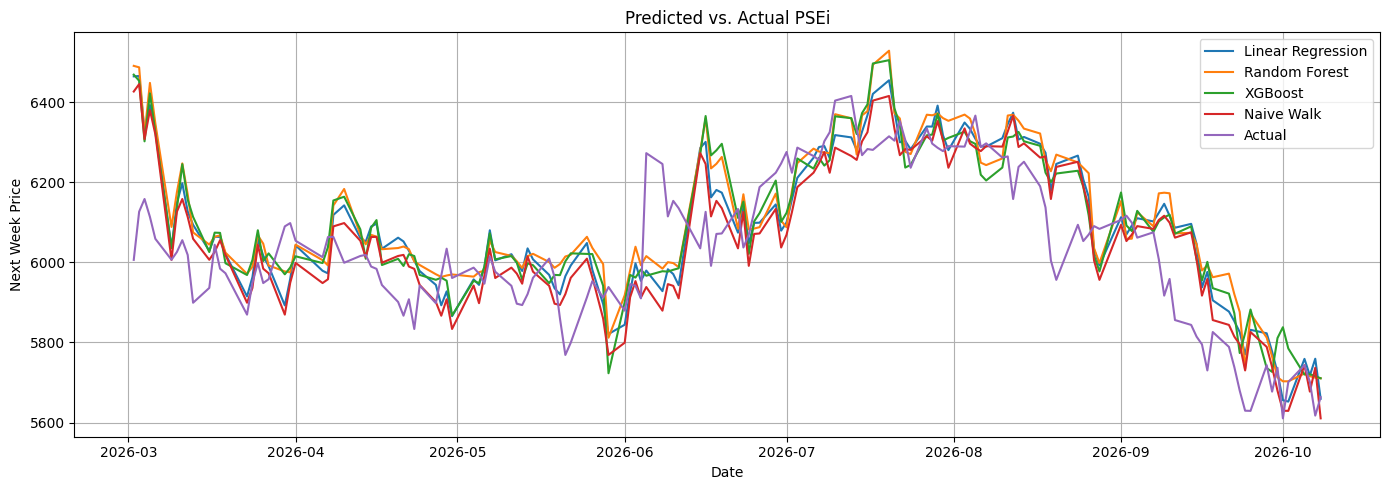

In [55]:
test_dates = psei_df.loc[Xr_test.index, "Date"]

plt.figure(figsize=(14, 5))

plt.plot(test_dates[:150], lr_predictions[:150], label="Linear Regression")
plt.plot(test_dates[:150], rf_predictions[:150], label="Random Forest")
plt.plot(test_dates[:150], xg_predictions[:150], label="XGBoost")
plt.plot(test_dates[:150], Xr_test['Price'][:150], label="Naive Walk")
plt.plot(test_dates[:150], yr_test[:150], label="Actual")

plt.title("Predicted vs. Actual PSEi")
plt.xlabel("Date")
plt.ylabel("Next Week Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **Interpretation of Metrics:**

* Linear Regression demonstrated the strongest overall performance. Although it had a slightly higher MAE than the Naive Walk, it achieved lower MSE and RMSE and a higher $R^2$, suggesting better overall predictive performance in these metrics.

* Random Forest and XGBoost produced results comparable to the Naive Walk baseline, although they did not surpass its predictive performance. This suggests that the additional complexity of these models did not necessarily translate into better forecasts given the available features and dataset. Nevertheless, their ability to approximate the baseline provides a useful point of comparison when evaluating the effectiveness of more complex forecasting approaches.

* The relatively large prediction errors may partly be attributed to the magnitude of PSEi values and the uncertainty associated with forecasting one week ahead. Market movements and external factors can introduce variations that the models cannot fully capture.

* Interestingly, Linear Regression, the simplest model among the three, performed best overall. This suggests that a linear model may be more appropriate for the selected features and dataset, as increasing model complexity did not necessarily improve predictive performance.

## **Conclusion**

This project demonstrated the application of machine learning in forecasting the PSEi's movement over the next five trading days using historical price data and technical indicators. Among the three models tested, Linear Regression achieved the strongest overall performance, outperforming the Naive Walk in most evaluation metrics. Meanwhile, Random Forest and XGBoost produced comparable results to the baseline, providing valuable insights into the effectiveness of more complex models for this forecasting task. Overall, the results highlight that simpler models can be competitive alternatives to more complex approaches, particularly given the selected features and forecasting distance of 5 days. While the models may serve as supplementary references for traders and investors, their predictions should not be treated as definitive and deterministic indicators of future market performance due to the inherent uncertainty and external factors influencing stock prices.

## **Yun lang hehe thx !! ^ _^ <33**